# Why finance is different: figures of Lesson 01.01

- This notebook generates the figures of the slides
  `Lesson01.01_Why_Finance_Is_Different.smd` from simulated data and closed-form
  curves, and saves them as PNG files
- The pedagogical arc:
  - Finance primer: option payoffs, drawdown, Sharpe ratio and leverage, market
    impact, and strategy capacity
  - Statistical properties of financial data: non-stationarity, heavy tails,
    volatility clustering, weak signals, and overfitting

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hintrospection as hintros
import helpers.hmatplotlib as hmatplo
import helpers.hnotebook as hnotebook

import L01_01_why_finance_is_different_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /Users/saggese/src/venv/client_venv.helpers/lib/python3.11/site-packages/ipykernel_launcher.py -f /private/var/folders/pd/0_nppqrn3cn7936mmhk37gcw0000gn/T/tmplb94zs9x.json --HistoryManager.hist_file=:memory:


In [3]:
# Directory of the figures, and prefix of the markdown reference to paste in the
# slides.
out_dir_name = "figures"
markdown_path_prefix = "book_Modern_AI_for_Finance/lectures_source"

# Figure sizes: a single panel fits a column of a slide, the two-panel figure
# needs more width.
figsize = (6.0, 4.0)
figsize_wide = (9.0, 4.0)

# Seed of all the simulations. It is chosen so that the simulated paths are
# representative of the average behavior, e.g., the sample autocorrelation of the
# squared returns is close to the median over seeds.
seed = 259

# Part 1: Finance primer

## Cell 1.1: Payoffs of a call and a put

**Goal**
- Show the payoff at expiration of a long call and a long put with one strike
- See that option payoffs are not linear in the spot price: the kink is at the
  strike

**Description**
- Inputs
  - `strike`: strike price $K$ shared by the call and the put
  - `figsize`: size of the figure, as (width, height) in inches

- Panels
  - `Payoff`: call payoff $\max(S_T - K, 0)$ in blue and put payoff
    $\max(K - S_T, 0)$ in red, against the spot price $S_T$

Saved figure to 'figures/L01.01.Option_Payoffs.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Option_Payoffs.png)


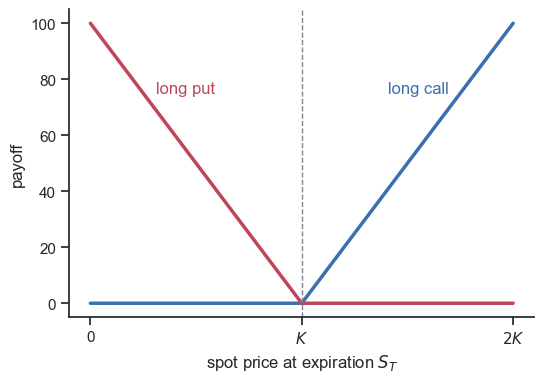

In [4]:
# Plot the payoff at expiration of a long call and a long put.
fig = utils.cell1_1_plot_option_payoffs(strike=100.0, figsize=figsize)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Option_Payoffs.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `strike` from 100 to 50
  - Observe the kink move to $K = 50$ and the x axis end at $2K = 100$, while
    both slopes stay equal to $\pm 1$

**Implementation** `cell1_1_plot_option_payoffs()`
- Builds a dataframe with the call and the put payoff on a grid of spot prices
  from 0 to $2K$
- Draws the two payoffs with `sns.lineplot()`
- Marks the strike with a dashed vertical line

In [5]:
hintros.print_obj_info(utils.cell1_1_plot_option_payoffs)

- `cell1_1_plot_option_payoffs(*, strike: float, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the payoff at expiration of a long call and a long put.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L87


## Cell 1.2: Equity curve and drawdown

**Goal**
- Define the drawdown, the maximum drawdown, and the drawdown duration on a
  simulated equity curve
- See that the deepest drawdown and the longest drawdown can be different
  episodes

**Description**
- Inputs
  - `n_days`: number of simulated days
  - `mean_return`: mean daily return of the strategy
  - `volatility`: daily volatility of the return
  - `seed`: seed of the random number generator

- Panels
  - `Equity`: equity curve in blue and its high watermark in dashed gray
  - `Max drawdown`: vertical red arrow from the high watermark to the trough,
    with the loss in percent
  - `Longest drawdown`: horizontal red arrow from a peak to the day that
    recovers it, with the duration in days

Saved figure to 'figures/L01.01.Drawdown.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Drawdown.png)


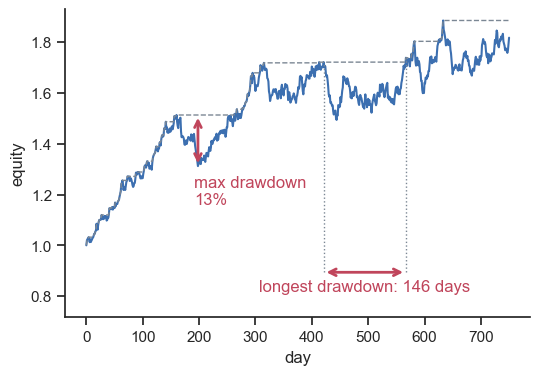

In [6]:
# Plot a simulated equity curve with its maximum and its longest drawdown.
fig = utils.cell1_2_plot_drawdown(
    n_days=750,
    mean_return=0.0006,
    volatility=0.01,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Drawdown.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Set `mean_return` to 0.0
  - Observe the curve stop trending up, the maximum drawdown deepen to 22%, and
    the longest drawdown last until the end of the sample
- Set `seed` to another value
  - Observe a new path with its own depth and duration: the two arrows often
    mark the same episode, and here they mark two different ones

**Implementation** `cell1_2_plot_drawdown()`
- Simulates IID Gaussian daily returns and compounds them with
  `_simulate_equity_curve()`
- Computes the high watermark and the drawdown with `_compute_drawdown()`
- Finds the deepest trough with `argmax()`, and the longest period between two
  peaks with `_find_longest_drawdown()`
- Draws the curve, the high watermark, and the two annotated arrows

In [7]:
hintros.print_obj_info(utils.cell1_2_plot_drawdown)

- `cell1_2_plot_drawdown(*, n_days: int, mean_return: float, volatility: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot an equity curve with its high watermark and its drawdowns.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L201


## Cell 1.3: Sharpe ratio and leverage

**Goal**
- Show that leverage moves a strategy along a line of constant Sharpe ratio
- See that a higher Sharpe ratio supports more return at the same volatility

**Description**
- Inputs
  - `risk_free`: risk-free rate per year
  - `excess_return`: expected excess return per year at 1x leverage
  - `volatility`: volatility per year at 1x leverage
  - `leverages`: leverage multiples to mark on the line

- Panels
  - `Sharpe line`: expected return against volatility, starting at $R_f$, with
    slope equal to the Sharpe ratio $SR$
  - `Markers`: the risk-free asset in orange and each leveraged strategy in blue

Saved figure to 'figures/L01.01.Sharpe_Leverage.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Sharpe_Leverage.png)


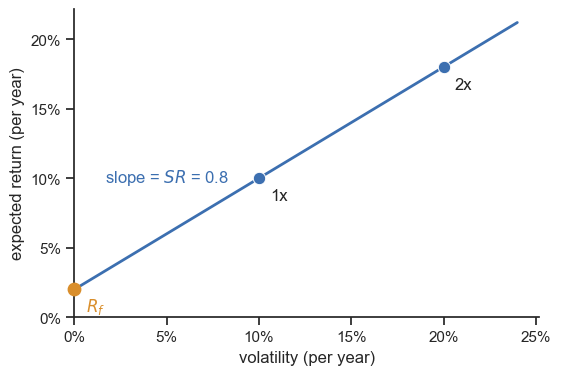

In [8]:
# Plot an 8% excess return and 10% volatility strategy at 1x and 2x leverage.
fig = utils.cell1_3_plot_sharpe_leverage(
    risk_free=0.02,
    excess_return=0.08,
    volatility=0.10,
    leverages=[1.0, 2.0],
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Sharpe_Leverage.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Add 3.0 to `leverages`
  - Observe a new point further up the same line: the slope stays $SR = 0.8$
- Raise `volatility` from 0.10 to 0.20, leaving `excess_return` fixed
  - Observe the line flatten to $SR = 0.4$, and the 1x point sit at the same
    return with twice the volatility

**Implementation** `cell1_3_plot_sharpe_leverage()`
- Computes $SR$ as the excess return divided by the volatility
- Scales excess return and volatility by each leverage, and adds $R_f$ to the
  return
- Draws the line of constant $SR$ and annotates each point

In [9]:
hintros.print_obj_info(utils.cell1_3_plot_sharpe_leverage)

- `cell1_3_plot_sharpe_leverage(*, risk_free: float, excess_return: float, volatility: float, leverages: List[float], figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the return and volatility of a strategy at different leverages.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L306


## Cell 1.4: Market impact of a buy order

**Goal**
- Split the price move around a buy order into a temporary and a permanent part
- See that only the permanent part is a lasting cost of trading

**Description**
- Inputs
  - `arrival_price`: price when the order arrives
  - `permanent`: permanent price impact, in dollars
  - `temporary`: peak temporary price impact, in dollars
  - `start`, `end`: execution window, in minutes
  - `decay_time`: time scale of the reversion of the temporary impact

- Panels
  - `Price path`: price in blue, rising during the execution and reverting
    afterwards
  - `Execution`: gray band over the execution window
  - `Impact`: red arrows for the temporary and the permanent component

Saved figure to 'figures/L01.01.Market_Impact.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Market_Impact.png)


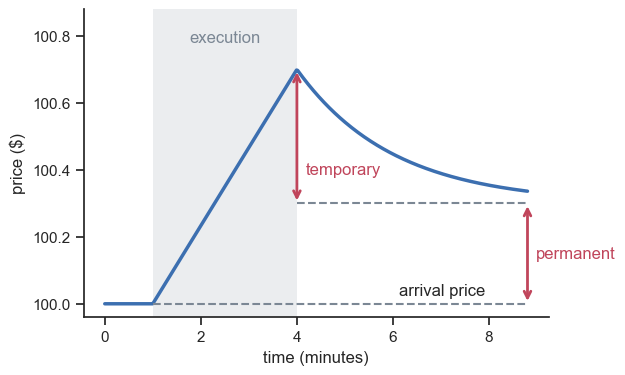

In [10]:
# Plot the price path of a buy order with a 0.30 permanent and a 0.40 temporary
# impact.
fig = utils.cell1_4_plot_market_impact(
    arrival_price=100.0,
    permanent=0.30,
    temporary=0.40,
    start=1.0,
    end=4.0,
    decay_time=2.0,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Market_Impact.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `temporary` from 0.4 to 0.8
  - Observe the peak at the end of the execution rise to 101.10, while the final
    level stays at 100.30
- Lower `decay_time` from 2.0 to 0.5
  - Observe the price settle on the permanent level within a few minutes of the
    end of the execution

**Implementation** `cell1_4_plot_market_impact()`
- Computes the fraction of the order executed at each time, from 0 to 1 over
  the execution window
- Adds the permanent impact and the temporary impact, which decays
  exponentially after the end of the execution
- Draws the path, the reference levels, and the two impact arrows

In [11]:
hintros.print_obj_info(utils.cell1_4_plot_market_impact)

- `cell1_4_plot_market_impact(*, arrival_price: float, permanent: float, temporary: float, start: float, end: float, decay_time: float, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the price path around a buy order, split into its impact components.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L399


## Cell 1.5: Strategy capacity

**Goal**
- Show gross PnL growing linearly with the book size, and impact cost growing
  faster
- See that net PnL peaks at the capacity of the strategy

**Description**
- Inputs
  - `gross_edge`: gross return of the strategy per year on the book
  - `capacity`: book size that maximizes the net PnL, in USD million

- Panels
  - `PnL curves`: gross edge in green, impact cost in red, and net PnL in blue
    as a function of the book size
  - `Capacity`: dashed lines at the book size and at the net PnL of the peak

Saved figure to 'figures/L01.01.Strategy_Capacity.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Strategy_Capacity.png)


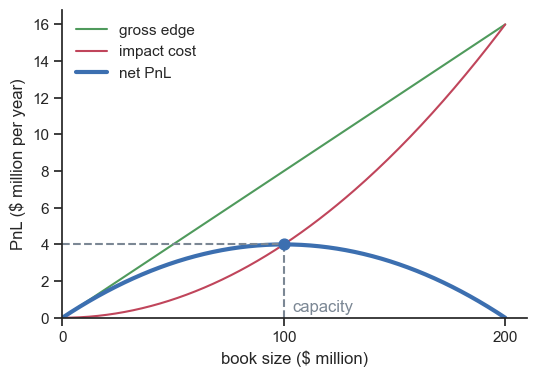

In [12]:
# Plot PnL against book size for an 8% gross edge and a USD 100 million capacity.
fig = utils.cell1_5_plot_strategy_capacity(
    gross_edge=0.08, capacity=100.0, figsize=figsize
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Strategy_Capacity.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `capacity` from 100 to 200, leaving `gross_edge` fixed
  - Observe the impact cost flatten, the peak move to a USD 200 million book,
    and the peak net PnL double to USD 8 million
- Lower `gross_edge` from 0.08 to 0.04, leaving `capacity` fixed
  - Observe the peak stay at a USD 100 million book, and the peak net PnL halve
    to USD 2 million

**Implementation** `cell1_5_plot_strategy_capacity()`
- Sets the impact coefficient so that net PnL $a B - c B^2$ peaks at the
  capacity, i.e., $c = a / (2 B^*)$
- Computes the three curves on a grid of book sizes from 0 to twice the
  capacity
- Draws the curves and marks the peak

In [13]:
hintros.print_obj_info(utils.cell1_5_plot_strategy_capacity)

- `cell1_5_plot_strategy_capacity(*, gross_edge: float, capacity: float, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot gross PnL, impact cost, and net PnL as a function of the book size.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L499


# Part 2: Statistical properties of financial data

## Cell 2.1: Prices against returns

**Goal**
- Contrast a non-stationary price with its approximately stationary return
- See that the price wanders away from its starting level while the return
  fluctuates around a constant mean

**Description**
- Inputs
  - `n_days`: number of simulated days
  - `mean_return`: mean daily return
  - `volatility`: daily volatility of the return
  - `seed`: seed of the random number generator

- Panels
  - `Price`: simulated price in orange, with its starting level in dashed gray
  - `Return`: daily return in blue, with its sample mean in dashed gray

Saved figure to 'figures/L01.01.Prices_vs_Returns.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Prices_vs_Returns.png)


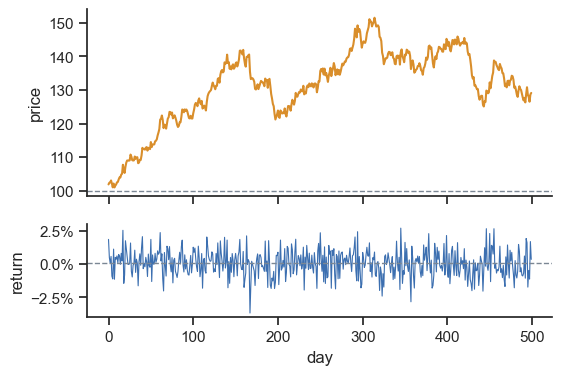

In [14]:
# Plot a simulated price path and its daily returns.
fig = utils.cell2_1_plot_prices_vs_returns(
    n_days=500,
    mean_return=0.0002,
    volatility=0.01,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Prices_vs_Returns.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `n_days` from 500 to 2000
  - Observe the price stay away from its starting level for long stretches,
    while the returns keep the same band around zero
- Raise `mean_return` from 0.0002 to 0.002
  - Observe the price trend up, while the return panel looks the same and only
    its mean line moves up

**Implementation** `cell2_1_plot_prices_vs_returns()`
- Draws IID Gaussian returns with `rng.normal()`
- Compounds them into a price with `np.cumprod()`, starting at 100
- Draws the price and the return on two panels that share the x axis

In [15]:
hintros.print_obj_info(utils.cell2_1_plot_prices_vs_returns)

- `cell2_1_plot_prices_vs_returns(*, n_days: int, mean_return: float, volatility: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot a simulated price path and its returns on two aligned panels.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L568


## Cell 2.2: Gaussian against heavy tails

**Goal**
- Compare the log density of a Gaussian and of a Student-t with the same
  variance
- See that the Student-t puts far more mass in the tails

**Description**
- Inputs
  - `degrees_of_freedom`: degrees of freedom of the Student-t, larger than 2

- Panels
  - `Log density`: Gaussian in blue and Student-t in red, both with unit
    variance, against the return in units of $\sigma$

Saved figure to 'figures/L01.01.Fat_Tails.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Fat_Tails.png)


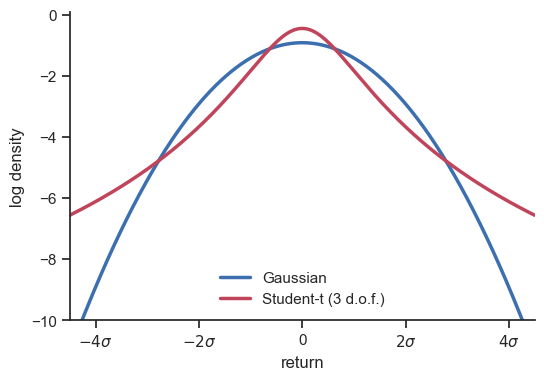

In [16]:
# Plot the log density of a Gaussian and of a Student-t with 3 degrees of freedom.
fig = utils.cell2_2_plot_fat_tails(degrees_of_freedom=3, figsize=figsize)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Fat_Tails.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `degrees_of_freedom` from 3 to 30
  - Observe the red curve approach the blue curve, with the tails coming closer
- Look at the curves at $\pm 4 \sigma$ for `degrees_of_freedom=3`
  - Observe the Student-t log density sit about 2.8 units above the Gaussian
    one, i.e., a density about 16 times larger

**Implementation** `cell2_2_plot_fat_tails()`
- Rescales the Student-t by $\sqrt{(\nu - 2) / \nu}$ so that its variance is 1
- Evaluates `sstats.norm.logpdf()` and `sstats.t.logpdf()` on a grid
- Draws the two curves in log scale, so that the tails are visible

In [17]:
hintros.print_obj_info(utils.cell2_2_plot_fat_tails)

- `cell2_2_plot_fat_tails(*, degrees_of_freedom: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the log density of a Gaussian and a Student-t with unit variance.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L634


## Cell 2.3: Volatility clustering

**Goal**
- Show that large moves follow large moves and calm follows calm
- See that returns with this pattern are not IID

**Description**
- Inputs
  - `n_obs`: number of simulated returns
  - `alpha`: weight of the previous squared return in the variance
  - `beta`: weight of the previous variance
  - `seed`: seed of the random number generator

- Panels
  - `Returns`: simulated GARCH(1,1) returns in percent, with zero in dashed gray

Saved figure to 'figures/L01.01.Volatility_Clustering.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Volatility_Clustering.png)


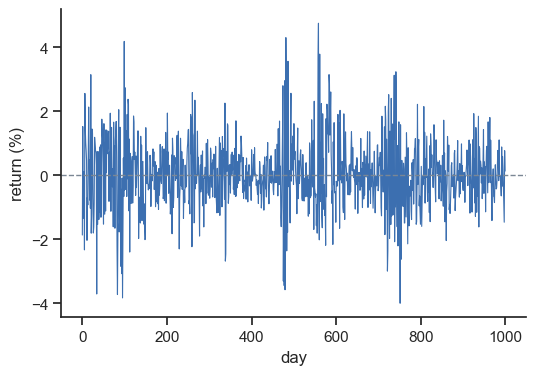

In [18]:
# Plot simulated GARCH(1,1) returns with unit unconditional variance.
fig = utils.cell2_3_plot_volatility_clustering(
    n_obs=1000, alpha=0.15, beta=0.80, seed=seed, figsize=figsize
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Volatility_Clustering.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Set `alpha` to 0.0 and `beta` to 0.0
  - Observe swings of constant size, with no calm or turbulent stretches
- Set `alpha` to 0.25 and `beta` to 0.70
  - Observe larger isolated spikes, since a large return raises the next
    variance more

**Implementation** `cell2_3_plot_volatility_clustering()`
- Simulates the GARCH(1,1) recursion with `_simulate_garch11()`, after a
  burn-in period
- Sets $\omega = 1 - \alpha - \beta$, so that the unconditional variance is 1
- Draws the return series with `sns.lineplot()`

In [19]:
hintros.print_obj_info(utils.cell2_3_plot_volatility_clustering)

- `cell2_3_plot_volatility_clustering(*, n_obs: int, alpha: float, beta: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot simulated GARCH(1,1) returns, where large moves follow large moves.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L727


## Cell 2.4: Returns against squared returns

**Goal**
- Show that returns are uncorrelated while squared returns are correlated
- See that volatility is easier to forecast than direction

**Description**
- Inputs
  - `n_obs`: number of simulated returns
  - `alpha`: weight of the previous squared return in the variance
  - `beta`: weight of the previous variance
  - `n_lags`: number of lags of the autocorrelation
  - `seed`: seed of the random number generator

- Panels
  - `Returns`: sample autocorrelation of returns in blue, with the 95% band of
    white noise in dashed gray
  - `Squared returns`: sample autocorrelation in red, with the theoretical
    GARCH(1,1) autocorrelation as a dotted curve

Saved figure to 'figures/L01.01.ACF_Returns_vs_Squared_Returns.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.ACF_Returns_vs_Squared_Returns.png)


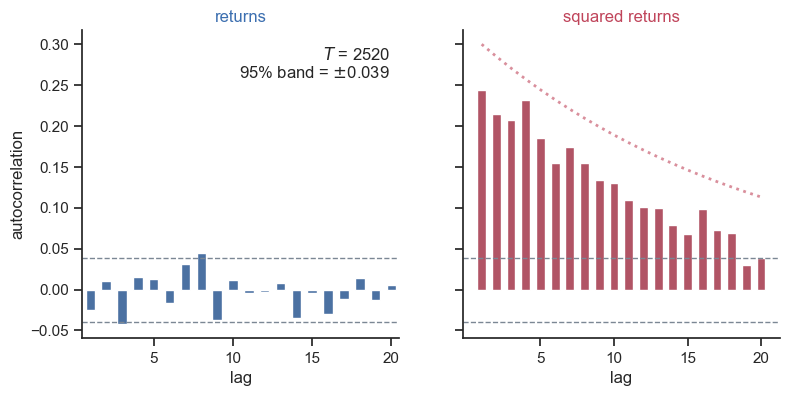

In [20]:
# Plot the autocorrelation of 10 years of daily GARCH(1,1) returns.
fig = utils.cell2_4_plot_returns_vs_squared_returns(
    n_obs=2520,
    alpha=0.15,
    beta=0.80,
    n_lags=20,
    seed=seed,
    figsize=figsize_wide,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.ACF_Returns_vs_Squared_Returns.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `n_obs` from 2520 to 10000
  - Observe the 95% band shrink to $\pm 0.020$, and the bars of the squared
    returns follow the dotted theory more closely
- Set `alpha` to 0.0 and `beta` to 0.0
  - Observe the dotted curve fall to zero and the squared returns stay near
    the band, like the returns

**Implementation** `cell2_4_plot_returns_vs_squared_returns()`
- Simulates GARCH(1,1) returns with `_simulate_garch11()`
- Computes the sample autocorrelation with `_compute_acf()`, for the returns
  and for their squares
- Computes the theoretical autocorrelation with
  `_compute_garch11_squared_acf()`
- Draws one bar panel per series, with the $\pm 1.96 / \sqrt{T}$ band

In [21]:
hintros.print_obj_info(utils.cell2_4_plot_returns_vs_squared_returns)

- `cell2_4_plot_returns_vs_squared_returns(*, n_obs: int, alpha: float, beta: float, n_lags: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the autocorrelation of returns and of squared returns side by side.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L801


## Cell 2.5: A weak signal in noise

**Goal**
- Show a forecast with an information coefficient of 0.05 against realized
  returns
- See that the signal explains a tiny fraction of the variance

**Description**
- Inputs
  - `n_obs`: number of forecast and return pairs
  - `information_coefficient`: true correlation of forecast and return
  - `seed`: seed of the random number generator

- Panels
  - `Scatter`: realized return against forecast, both standardized
  - `Fit`: least squares line in red
  - `Comments`: true IC, sample IC, and $R^2$

Saved figure to 'figures/L01.01.Weak_Signal.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Weak_Signal.png)


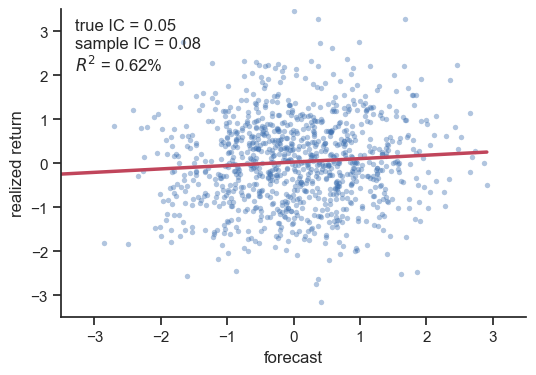

In [22]:
# Plot realized returns against forecasts with a true IC of 0.05.
fig = utils.cell2_5_plot_weak_signal(
    n_obs=1000, information_coefficient=0.05, seed=seed, figsize=figsize
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Weak_Signal.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `information_coefficient` from 0.05 to 0.5
  - Observe the cloud tilt, the line steepen, and $R^2$ rise to about 27%
- Lower `n_obs` from 1000 to 50
  - Observe the sample IC move far from 0.05, since its standard error is
    about 0.14

**Implementation** `cell2_5_plot_weak_signal()`
- Draws a standardized forecast and independent noise with `rng.standard_normal()`
- Builds the return as $IC \cdot f + \sqrt{1 - IC^2} \cdot \epsilon$, so that
  the correlation equals the IC
- Draws the scatter with `sns.scatterplot()` and the fit with `sns.regplot()`

In [23]:
hintros.print_obj_info(utils.cell2_5_plot_weak_signal)

- `cell2_5_plot_weak_signal(*, n_obs: int, information_coefficient: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot realized returns against forecasts for a given information coefficient.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L874


## Cell 2.6: Overfitting noise

**Goal**
- Show in-sample error falling with model complexity while out-of-sample error
  turns up
- See that adding noise features is harmful, not just useless

**Description**
- Inputs
  - `n_train`: number of training observations
  - `n_features`: number of candidate features
  - `n_signal`: number of features that drive the target
  - `seed`: seed of the random number generator

- Panels
  - `Errors`: mean squared error against the number of features, in-sample in
    blue and out-of-sample in red
  - `Optimal`: dashed line at the number of features with the lowest
    out-of-sample error

Saved figure to 'figures/L01.01.Overfitting.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L01.01.Overfitting.png)


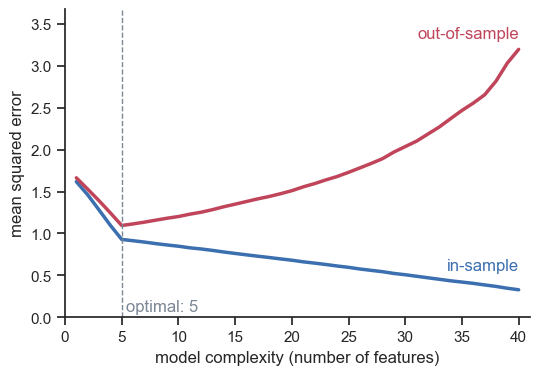

In [24]:
# Plot in-sample and out-of-sample error of nested linear models.
fig = utils.cell2_6_plot_overfitting(
    n_train=60, n_features=40, n_signal=5, seed=seed, figsize=figsize
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L01.01.Overfitting.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Raise `n_train` from 60 to 240
  - Observe the out-of-sample error at 40 features fall from about 3.2 to 1.2,
    since more data supports more features
- Set `n_signal` to 0
  - Observe the out-of-sample error rise from the first feature, with the
    optimum at 1 feature, while the in-sample error still falls

**Implementation** `cell2_6_plot_overfitting()`
- Simulates 200 datasets in which only the first `n_signal` features drive the
  target
- Fits least squares on the first $k$ features with `np.linalg.lstsq()`, for
  each $k$
- Averages the in-sample and out-of-sample squared error over the datasets
- Draws the two curves and marks the best $k$

In [25]:
hintros.print_obj_info(utils.cell2_6_plot_overfitting)

- `cell2_6_plot_overfitting(*, n_train: int, n_features: int, n_signal: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot in-sample and out-of-sample error against the model complexity.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L01_why_finance_is_different/L01_01_why_finance_is_different_utils.py#L992
